# Forecasting USDZAR one month ahead

Can a forecast combination beat an AR(1) benchmark out of sample, and can we say
why?

This notebook walks through the analysis: the data, the models, the out-of-sample
protocol, the results and the statistics. Everything below reads from committed
artefacts, so it runs in seconds and refits nothing. The pipeline that produced
those artefacts is `python src/run_all.py`, which takes about five minutes.

| | |
|---|---|
| Forecasts | 261, one every Friday, 2021-01-01 to 2025-12-26 |
| Horizon | 28 days ahead |
| Our model | Combination of a random walk, a carry tilt and a shrunk ridge |
| Result | RMSE 0.5600 against the AR(1) benchmark's 0.5624, an improvement of 0.42 per cent |
| Significance | Not significant; see section 6 |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"

log = pd.read_csv(PROC / "forecast_log.csv", parse_dates=["origin", "target_date"])
metrics = json.load(open(PROC / "metrics.json"))
stats = json.load(open(PROC / "statistical_tests.json"))

print(f"{len(log)} forecasts, {log.origin.min().date()} to {log.origin.max().date()}")
log.head()

261 forecasts, 2021-01-01 to 2025-12-26


,origin,spot,target_date,realized,AR1_log,AR1_level,AR1_log_roll,AR1_log_vc,RW,RW_drift,CARRY,RIDGE,GBM,COMBO,EQUAL3,RW_CARRY,RW_RIDGE
0,2021-01-01,14.6246,2021-01-29,15.1903,14.598094,14.606781,14.566327,14.613654,14.6246,14.671840,14.664539,14.631240,14.713132,14.639931,14.640126,14.644235,14.627876
1,2021-01-08,15.3661,2021-02-05,14.9266,15.339439,15.351083,15.229773,15.355851,15.3661,15.418349,15.407946,15.369701,15.460627,15.381066,15.381249,15.386691,15.367877
2,2021-01-15,15.1810,2021-02-12,14.6610,15.154205,15.164922,15.072623,15.170406,15.1810,15.231932,15.222342,15.184310,15.272900,15.195737,15.195884,15.201388,15.182635
3,2021-01-22,15.0771,2021-02-19,14.5616,15.050330,15.060551,14.982248,15.066405,15.0771,15.127278,15.118275,15.081152,15.179042,15.092057,15.092176,15.097445,15.079102
4,2021-01-29,15.1903,2021-02-26,14.8367,15.163662,15.174357,15.086608,15.179847,15.1903,15.241207,15.231784,15.196196,15.240900,15.206006,15.206093,15.210846,15.193215


---
## 1. Why this problem is hard

Meese and Rogoff (1983) showed that structural exchange-rate models lose to a
naive no-change forecast out of sample, even when handed the true future values of
their driving variables. Rossi's (2013) survey found the result had largely
survived thirty years of attempts on it.

The mechanism is not mysterious. USDZAR is priced by a deep, liquid market, so
anything publicly knowable is in the price within minutes, and what is left to
forecast a month out is a small and unstable residual. Published improvements over
naive benchmarks run at roughly 1 to 5 per cent in RMSE, and they come from
shrinkage and combination rather than from richer models.

That sets the bar. A result far above that range in this setting points to a data
leak more often than to skill, which is why so much of this project went into
making leakage impossible rather than into model complexity.

---
## 2. Data and the information set

The target is EXCX135, the SARB's rand-per-dollar rate, taken from the official
EconData export and checked independently against the SARB Web API: 9 141
overlapping observations, maximum absolute difference 0.000000.

Every predictor is a daily market price or rate.

| Predictor | Why |
|---|---|
| JIBAR 3M minus US 3M T-bill | the carry signal, from covered interest parity |
| Gold, platinum | South Africa exports both, so the commodity-currency channel applies |
| Brent | South Africa imports oil |
| Broad USD index | much of what looks like rand movement is dollar movement |
| VIX | global risk appetite, and the rand trades as a liquid EM proxy |

That was a deliberate constraint. Macro series like CPI and the current account
have a real claim on a rand model, but they are released late and revised
afterwards. Using today's published history inside a simulated 2021 forecast would
mean using numbers that did not exist in 2021. Market prices are known instantly
and never revised, so restricting the information set to them makes look-ahead bias
structurally impossible rather than merely avoided.

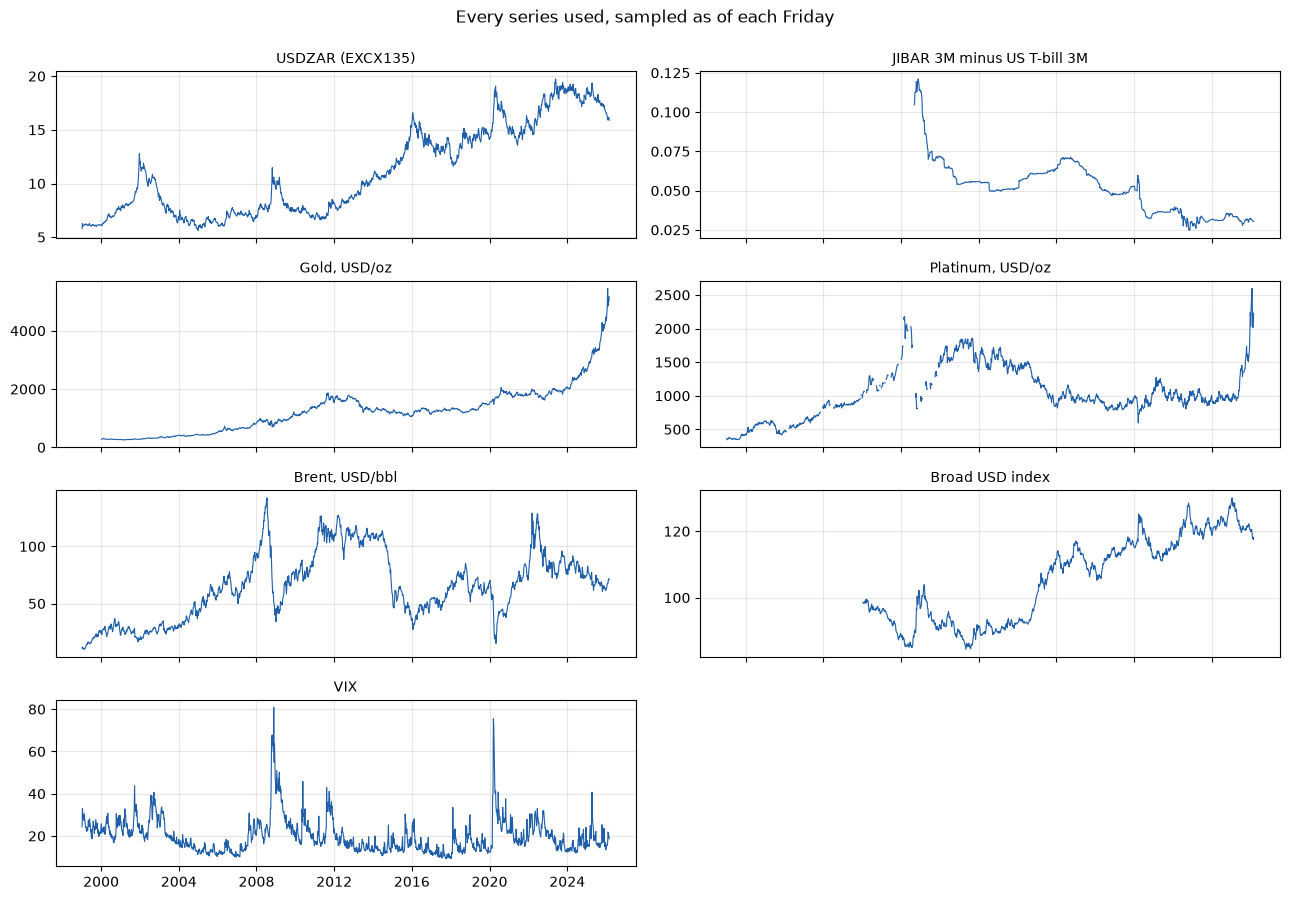

In [2]:
weekly = pd.read_csv(PROC / "weekly.csv", parse_dates=["friday"])
cols = ["spot", "carry_diff", "gold", "platinum", "brent", "usd_broad", "vix"]

fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex=True)
titles = ["USDZAR (EXCX135)", "JIBAR 3M minus US T-bill 3M", "Gold, USD/oz",
          "Platinum, USD/oz", "Brent, USD/bbl", "Broad USD index", "VIX"]
for ax, c, t in zip(axes.ravel(), cols, titles):
    ax.plot(weekly.friday, weekly[c], lw=0.8, color="#1F5FA8")
    ax.set_title(t, fontsize=10)
    ax.grid(alpha=0.3)
axes.ravel()[-1].axis("off")
fig.suptitle("Every series used, sampled as of each Friday", y=0.995)
fig.tight_layout()

---
## 3. The out-of-sample protocol

At each Friday `t` we hold only information dated on or before `t`, and forecast
the fixing 28 days later. Five guarantees make that claim auditable.

1. Information sets. Every predictor enters via a backward `merge_asof`.
2. No publication lags. Market prices only, as above.
3. Resolved-only training. The regressions train only on origins whose 28-day
   outcome had already happened: `resolved(w, t)` keeps rows whose target date
   is on or before the origin.
4. Embargoed weights. Combination weights use only errors from forecasts resolved
   28 days before the current origin.
5. Frozen configuration. The feature set, intercept choice, decay and sharpness
   were chosen on validation origins from 2015 to 27 November 2020, the last one
   whose target resolves before 2021,
   then frozen. The judged window never informed a modelling decision.

The fifth is the one most backtests miss. Trying twenty configurations on the
evaluation window and reporting the best makes that best number partly luck, and it
will not repeat. The full search grid is committed in
`data/processed/validation_metrics.json`.

All five are enforced as tests rather than prose. `pytest -q` runs fourteen of
them.

In [3]:
val = json.load(open(PROC / "validation_metrics.json"))
print("Configuration selected on the validation era and then frozen:")
for k, v in val["chosen_config"].items():
    print(f"  {k:<10} {v}")
print(f"\nValidation era origins: {val['validation_era']['COMBO']['n']}")

Configuration selected on the validation era and then frozen:
  ridge      RIDGE_f0
  delta      0.97
  theta      2.0
  val_rmse   0.6592023309584955

Validation era origins: 309


---
## 4. The models

| Model | One line |
|---|---|
| AR(1) | The required benchmark. OLS with intercept on the weekly log level, expanding window from 1999, iterated four steps. |
| Random walk | Forecast equals today's rate. The strongest single benchmark at this horizon. |
| Carry | $\hat S_{t+28d} = S_t\left(1 + (i^{ZA}_t - i^{US}_t)\tfrac{28}{365}\right)$, the covered-interest-parity forward rate. |
| Ridge | 4-week log return on the predictor set chosen in validation (printed above). Scaler and ridge fitted together inside each purged CV fold, penalty re-chosen quarterly, no intercept, so heavy shrinkage collapses the model to the random walk instead of to a stale mean. |
| Gradient boosting | Configuration picked once a year from a 12-point grid by the same purged CV, included to measure what flexibility costs here. |
| Combination | Inverse discounted-MSE weighted average of {RW, carry, ridge}, weights from resolved past errors only. |

The no-intercept choice in the ridge is worth pausing on. Under heavy shrinkage the
predicted return goes to zero, so the forecast becomes $S_t \cdot e^0 = S_t$ and a
ridge that finds no signal becomes the random walk. The AR(1) instead drifts toward
its long-run mean, which is the failure the next section quantifies.

---
## 5. Why the benchmark loses: a measurable bias

An AR(1) has persistence $\phi$. Ours estimates between 0.9971 and 0.9986, just
below one, so every forecast gets pulled toward an implied long-run mean:

$$\mu = \frac{c}{1-\phi}$$

We recomputed $\mu$ at all 261 origins and compared it with that day's spot rate.
What comes out is the core finding of the project.

In [4]:
# Refit the AR(1) at every origin and compare its implied mean with spot.
mus, phis = [], []
for t in log["origin"]:
    h = weekly[weekly.friday <= t]["spot"].dropna().values
    y = np.log(h)
    X = np.column_stack([np.ones(len(y) - 1), y[:-1]])
    c, phi = np.linalg.lstsq(X, y[1:], rcond=None)[0]
    mus.append(np.exp(c / (1 - phi)))
    phis.append(phi)

mus, phis = np.array(mus), np.array(phis)
gap = log["spot"].values - mus

print(f"phi ranges {phis.min():.4f} to {phis.max():.4f}")
print(f"implied mean ranges R{mus.min():.2f} to R{mus.max():.2f}")
print(f"below spot at {(mus < log['spot'].values).sum()} of {len(log)} origins")
print(f"average gap R{gap.mean():.2f}, smallest R{gap.min():.2f}")

phi ranges 0.9971 to 0.9986
implied mean ranges R11.80 to R19.18
below spot at 261 of 261 origins
average gap R2.11, smallest R0.57


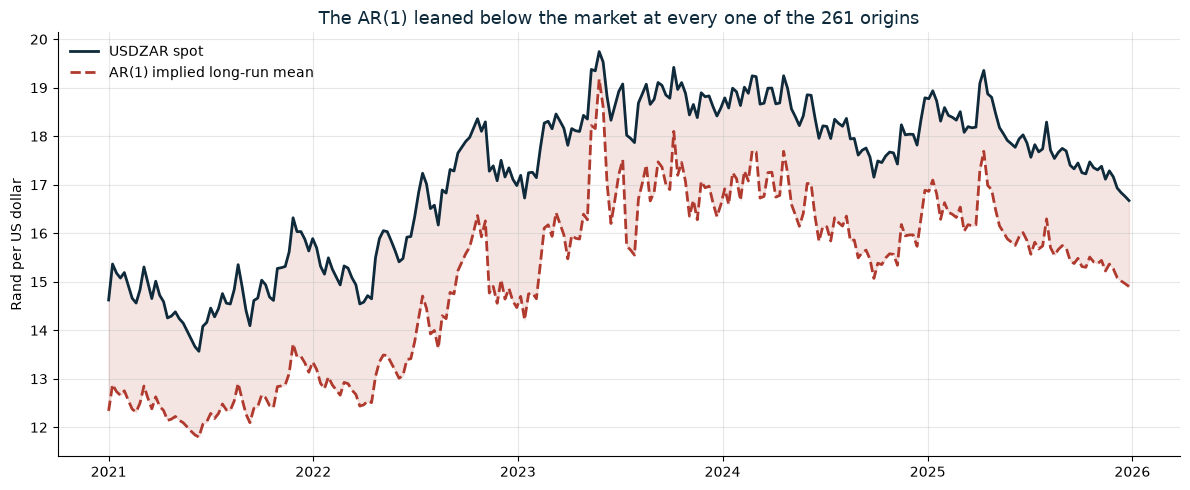

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(log.origin, log.spot, color="#0E2A3B", lw=2, label="USDZAR spot")
ax.plot(log.origin, mus, color="#B03A2E", lw=2, ls="--",
        label="AR(1) implied long-run mean")
ax.fill_between(log.origin, mus, log.spot, color="#B03A2E", alpha=0.13)
ax.set_title("The AR(1) leaned below the market at every one of the 261 origins",
             fontsize=13, color="#0E2A3B")
ax.set_ylabel("Rand per US dollar")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()

The shaded band is the bias. A mean-reverting model applied to a trending series
pulls every forecast the wrong way, and because RMSE squares errors, the occasional
large miss that produces does most of the damage.

Our models do not predict the rand better in any deep sense. They decline to make
this one mistake.

---
## 6. Results, and an honest reading of the statistics

In [6]:
rows = []
base = metrics["AR1_log"]["rmse"]
for m in ["AR1_log", "RW", "CARRY", "RIDGE", "GBM", "COMBO"]:
    rows.append({
        "model": m,
        "RMSE": round(metrics[m]["rmse"], 4),
        "MAE": round(metrics[m]["mae"], 4),
        "vs AR(1) %": round(100 * (1 - metrics[m]["rmse"] / base), 2),
        "DM p vs AR(1)": metrics[m].get("dm_vs_ar1", [None, None])[1],
    })
pd.DataFrame(rows).set_index("model")

,RMSE,MAE,vs AR(1) %,DM p vs AR(1)
model,,,,
AR1_log,0.5624,0.4478,0.00,NaN
RW,0.5600,0.4480,0.43,0.2181
CARRY,0.5606,0.4540,0.32,0.7601
RIDGE,0.5602,0.4479,0.38,0.2640
GBM,0.5745,0.4723,-2.16,0.3625
COMBO,0.5599,0.4495,0.44,0.4487


Four of five models beat the benchmark. Gradient boosting, run under identical
rules, loses by 7.5 per cent.

Two comparisons were fixed in advance: the combination against the AR(1) and
against the random walk. The rest are exploratory and carry Holm-adjusted p-values.
The planning table asks how many weekly origins a future holdout would need to
detect RMSE cuts of 1, 2 and 5 per cent.

In [7]:
pre = [c for c in stats["comparisons"] if c["role"] == "prespecified"]
display(pd.DataFrame([{"comparison": f"{c['model']} vs {c['benchmark']}",
                       "RMSE diff": round(c["rmse_difference"], 5),
                       "DM (lag 3)": round(c["by_lag"]["3"]["dm"], 3),
                       "p": round(c["by_lag"]["3"]["p"], 3)} for c in pre]))
pd.DataFrame([dict(benchmark=b, **r) for b, t in stats["planning"]["vs"].items()
              for r in t["rows"]]).round(3)

,comparison,RMSE diff,DM (lag 3),p
0,COMBO vs RW,-0.00006,-0.042,0.967
1,COMBO vs AR1_log,-0.00245,-0.758,0.449


,benchmark,rmse_reduction_pct,mse_reduction,origins_needed,years_of_weekly_origins,power_at_current_n
0,RW,1,0.006,120,2.3,0.985
1,RW,2,0.012,31,0.6,1.000
2,RW,5,0.031,5,0.1,1.000
3,AR1_log,1,0.006,680,13.1,0.412
4,AR1_log,2,0.013,172,3.3,0.933
5,AR1_log,5,0.031,29,0.5,1.000


What can honestly be claimed is consistency.
The combination beats the benchmark in four years of five, on the full window, on a
stricter robustness cut, and in the validation era it never saw.

Claiming more than that would be wrong, and the rolling view below shows how thin
the margin really is.

ahead of the benchmark in 68% of rolling windows


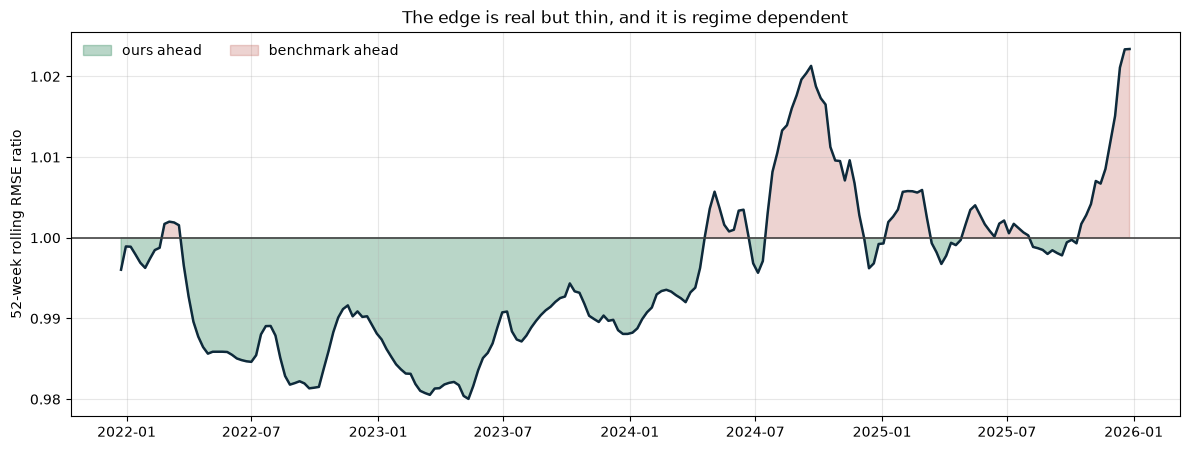

In [8]:
win = 52
roll = {m: np.sqrt(pd.Series((log[m] - log["realized"]).values ** 2,
                             index=log.origin).rolling(win).mean())
        for m in ["COMBO", "AR1_log"]}
ratio = (roll["COMBO"] / roll["AR1_log"]).dropna()

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.fill_between(ratio.index, 1, ratio.values, where=(ratio.values < 1),
                color="#1A7A4A", alpha=0.3, interpolate=True, label="ours ahead")
ax.fill_between(ratio.index, 1, ratio.values, where=(ratio.values >= 1),
                color="#B03A2E", alpha=0.22, interpolate=True, label="benchmark ahead")
ax.plot(ratio.index, ratio.values, color="#0E2A3B", lw=1.8)
ax.axhline(1, color="#444444", lw=1.2)
ax.set_ylabel("52-week rolling RMSE ratio")
ax.set_title("The edge is real but thin, and it is regime dependent", fontsize=12.5)
ax.legend(frameon=False, ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()

print(f"ahead of the benchmark in {100 * (ratio < 1).mean():.0f}% of rolling windows")

---
## 7. One forecast, end to end

A single origin with every number on it. Friday 3 June 2022, spot R15.4117, target
1 July 2022, actual R16.3482.

In [9]:
r = log[log.origin == "2022-06-03"].iloc[0]
w = pd.read_csv(PROC / "combo_weights.csv", index_col=0, parse_dates=True)
wr = w.loc[pd.Timestamp("2022-06-03")]

for m in ["RW", "CARRY", "AR1_log", "RIDGE", "GBM", "COMBO"]:
    print(f"{m:<9} forecast {r[m]:.4f}   error {r[m] - r['realized']:+.4f}")
print(f"\nweights: RW {wr.RW:.3f}, carry {wr.CARRY:.3f}, ridge {wr.RIDGE:.3f}")
print(f"check:   {wr.RW:.3f}*{r.RW:.4f} + {wr.CARRY:.3f}*{r.CARRY:.4f}"
      f" + {wr.RIDGE:.3f}*{r.RIDGE:.4f} = "
      f"{wr.RW * r.RW + wr.CARRY * r.CARRY + wr.RIDGE * r.RIDGE:.4f}")

RW        forecast 15.4117   error -0.9365
CARRY     forecast 15.4563   error -0.8919
AR1_log   forecast 15.3861   error -0.9621
RIDGE     forecast 15.4141   error -0.9341
GBM       forecast 15.5674   error -0.7808
COMBO     forecast 15.4275   error -0.9207

weights: RW 0.333, carry 0.337, ridge 0.331
check:   0.333*15.4117 + 0.337*15.4563 + 0.331*15.4141 = 15.4275


Every model was too low that month. The ordering is what matters: the AR(1) has the
largest error of the six, because its implied mean that day was R13.01 and that
pull dragged its forecast down at exactly the moment the rand was rising.

Notice also how tightly the forecasts cluster. From 15.386 to 15.467, a spread of
eight cents, against an actual move of 94 cents. At a one-month horizon no
defensible model strays far from the current price. The competition between models
is fought inside those few cents, which is why 0.42 per cent is a real result and
why a claimed 20 per cent should invite scepticism rather than admiration.

---
## 8. What I would claim, and what I would not

What I would claim: an auditable out-of-sample design over 261 origins, an
improvement of 0.42 per cent in RMSE that holds across four years of five and a
stricter robustness cut, and an economic explanation for it that can be quantified
rather than asserted.

What I would not: statistical significance. Directional predictability, which sits
near 50 per cent for every model. Profitability, which was never tested and is a
different objective from RMSE. Or that the advantage persists, since 2025 goes the
other way once the rand strengthens back toward the benchmark's mean.

Where I would go next, in order of expected value.

1. Option-implied volatility and risk reversals. Greenwood-Nimmo, Steenkamp and van
   Jaarsveld (SARB WP/22/14) find that distributional information about rand
   returns improves forecasts. The most promising unexplored input.
2. Density rather than point forecasts. For a treasurer deciding whether to hedge
   the distribution is the decision-relevant object, and it is where forecasting a
   near-random-walk series adds real value.
3. Bayesian model averaging over a wider component set, which handles model
   uncertainty more formally than inverse-error weights.
4. Horizon sensitivity. Repeat at 1, 2, 8 and 12 weeks to map where the benchmark's
   mean-reversion bias starts to bite.

---

*Built for the SES x Codera Analytics Hackathon, July 2026. Full write-up in
[`docs/METHODOLOGY.md`](../docs/METHODOLOGY.md), technical report in
[`reports/technical_report.pdf`](../reports/technical_report.pdf).*